# Лабораторная работа 6. Использование внешних библиотек в ассемблере

Разработать программу на языке ассемблере с использованием библиотеки **ncurses**, в которой курсор перемещается по экрану в соответствии с заданным алгоритмом и оставляет за собой след заданного цвета, по достижению границы движение продолжается  с начальной позиции с заполнением другим заданным цветом. Предусмотреть заданную клавишу выхода из программы, а также заданную клавишу, регулирующую скорость движения.

- Движение 2:

![image.png](attachment:72fa9ed0-f2b1-4e26-b481-65cfe1e56c6c.png)


In [1]:
import random as rd

Variant = 14
rd.seed(Variant)


colors = ['COLOR_BLACK', 'COLOR_RED', 'COLOR_GREEN', 'СOLOR_YELLOW', 'COLOR_BLUE', 'COLOR_MAGENTA', 'COLOR_CYAN', 'COLOR_WHITE']
buttons = ['q', 'w', 'e', 'r', 't', 'y', 'u', 'i', 'o', 'p', 'a', 's', 'd', 'f', 'g', 'h', 'j','k','l','z','x','c','v','b','n','m']
print("Алгоритм: " , rd.sample([1,2,3,4,5,6,7,8],1))
print("Цвета заполнения: " , rd.sample(colors,2))
print("Кнопки выхода, изменения скорости: " , rd.sample(buttons,2))

Алгоритм:  [2]
Цвета заполнения:  ['СOLOR_YELLOW', 'COLOR_GREEN']
Кнопки выхода, изменения скорости:  ['b', 'o']


In [ ]:
format ELF64

	public _start

	extrn initscr
	extrn start_color
	extrn init_pair
	extrn getmaxx
	extrn getmaxy
	extrn noecho
	extrn stdscr
	extrn move
	extrn getch
	extrn addch
	extrn refresh
	extrn endwin
	extrn exit
	extrn cbreak
	extrn timeout
    extrn usleep


	section '.bss' writable

	xmax dq 1 ; число столбцов экрана
	ymax dq 1 ; число строк экрана
    x dq 1 ; текущий столбец
    y dq 1 ; текущая строка
    delta_y dq 1 ; вертикальный шаг: -1 вверх, +1 вниз
	palette dq 1 ; символ пробела с цветовым атрибутом
    delay dq 100000 ; задержка в микросекундах, изначально 100 мс

    section '.text' executable
        _start:

            call initscr ; инициализировать экран ncurses
            call noecho ; отключить отображение вводимых символов
            call cbreak ; получать ввод без ожидания Enter


            xor rdi, rdi ; обнулить первый аргумент
            mov rdi, [stdscr] ; передать указатель на основное окно
            call getmaxx ; получить число столбцов в eax
            mov [xmax], rax ; сохранить ширину экрана
            mov rdi, [stdscr] ; передать указатель на основное окно
            call getmaxy ; получить число строк в eax
            mov [ymax], rax ; сохранить высоту экрана

            call start_color ; включить работу с цветами


            mov rdi, 1 ; номер первой цветовой пары
            mov rsi, 3 ; жёлтый цвет символа
            mov rdx, 3 ; жёлтый цвет фона
            call init_pair ; зарегистрировать цветовую пару


            mov rdi, 2 ; номер второй цветовой пары
            mov rsi, 2 ; зелёный цвет символа
            mov rdx, 2 ; зелёный цвет фона
            call init_pair ; зарегистрировать цветовую пару

            mov rax, 0x20 ; код пробела в младших 8 битах
            or rax, 0x100 ; добавляем номер первой цветовой пары в биты с 8 по 15
            mov [palette], rax ; сохраняем в переменную типа chtype

            mov rax, [xmax] ; загрузить число столбцов
            dec rax ; получить последний допустимый индекс
            mov [x], rax ; установить крайний правый столбец

            mov rax, [ymax] ; загрузить число строк
            dec rax ; получить последний допустимый индекс
            mov [y], rax ; установить нижнюю строку

            mov qword [delta_y], -1 ; задать движение вверх

            mov edi, 0 ; нулевое ожидание ввода
            call timeout ; настроить неблокирующий getch

        .main_loop:
            mov rdi, [y] ; передаем текущие координаты клетки для отрисовки
            mov rsi, [x]
            call move ; переместить курсор в точку с текущими координатами

            mov rdi, [palette] ; передать пробел с цветовым атрибутом
            call addch ; отрисовать символ с атрибутами в терминале
            call refresh ; показать изменения в терминале

            mov rdi, [delay] ; передать текущую задержку
            call usleep ; выдержать паузу между шагами

            .wait_key: ; обработка ввода
                call getch ; прочитать клавишу или получить ERR при отсутствии ввода
                cmp eax, 'b' ; проверить клавишу выхода
                jne .accelerate ; если это не b, проверить изменение скорости

                call endwin ; восстановить обычный режим терминала
                xor rdi, rdi ; передать нулевой код завершения
                call exit ; завершить процесс с переданным кодом

            .accelerate: ; проверка изменения скорости
                cmp eax, 'o' ; проверить клавишу ускорения
                jne .next ; при другой клавише перейти к движению

                cmp qword [delay], 10000 ; проверить достижение минимальной задержки
                jle .reset_delay ; при достижении предела сбросить задержку до начальной

                sub qword [delay], 10000 ; уменьшить задержку на 10 мс
                jmp .next ; перейти к расчёту следующей позиции

                .reset_delay: ; возврат начальной скорости
                    mov qword [delay], 100000 ; восстановить задержку 100 мс
                    jmp .next ; перейти к расчёту следующей позиции

            .next: ; расчёт следующей позиции
                mov rbx, [y] ; загрузить текущую строку
                add rbx, [delta_y] ; вычислить предполагаемую следующую координату

                cmp rbx, 0 ; проверить верхнюю границу
                jl .turn_left ; при выходе выше экрана перейти к повороту
                cmp rbx, [ymax] ; проверить нижнюю границу
                jge .turn_left ; при выходе ниже экрана перейти к повороту
                mov [y], rbx ; иначе обновить текущую ординату
                jmp .main_loop ; перейти к отрисовке следующей клетки

            .turn_left: ; переход в соседний столбец
                cmp [x], 0 ; проверить достижение первого столбца терминала
                jle .beginning ; перейти в начальную точку цикла змейки
                sub [x], 1 ; сдвинуться влево
                neg qword [delta_y] ; поменять направление движения по вертикали
                jmp .main_loop ; перейти к отрисовке следующей клетки

            .beginning: ; начало нового прохода по экрану
                mov rax, [xmax] ; загрузить число столбцов
                dec rax ; получить последний допустимый индекс
                mov [x], rax ; восстанавливаем абсциссу начальной точки цикла
                mov rax, [ymax] ; загрузить число строк
                dec rax ; получить последний допустимый индекс
                mov [y], rax ; восстанавливаем ординату начальной точки цикла
                mov qword [delta_y], -1 ; задать движение вверх

                xor qword [palette], 0x300 ; переключить палитру
                jmp .main_loop ; перейти к отрисовке следующей клетки


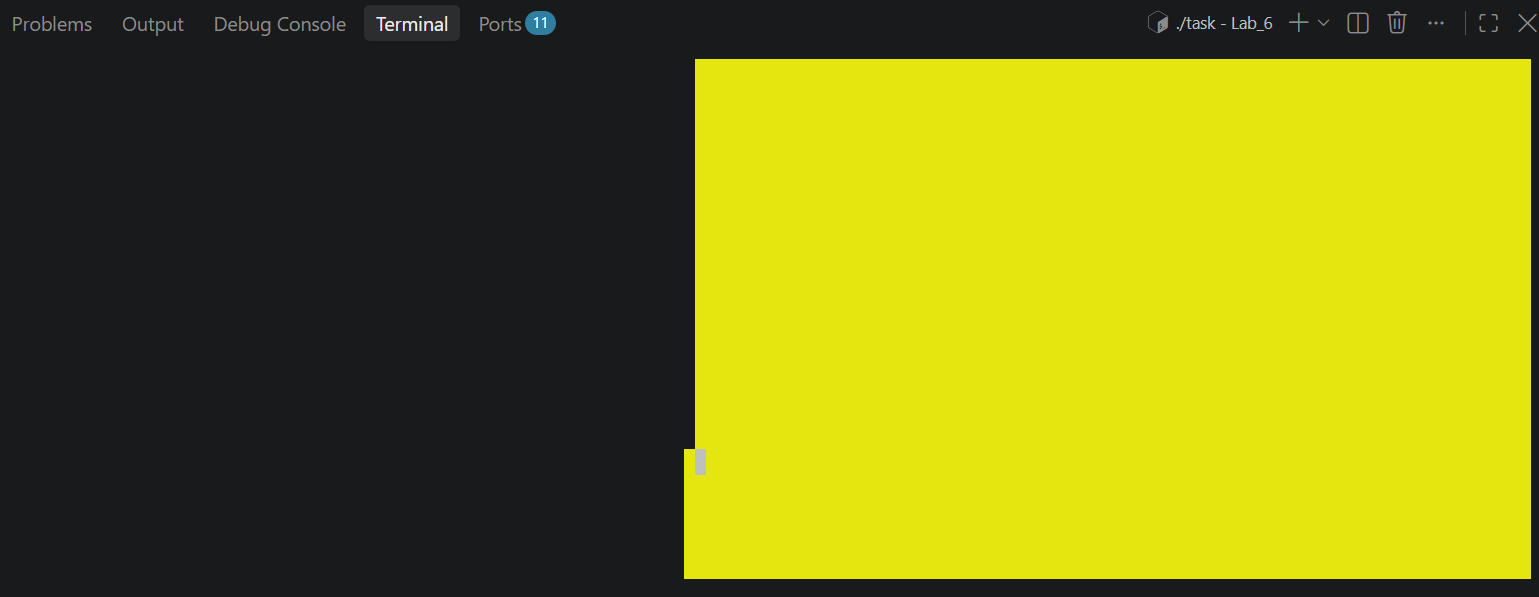
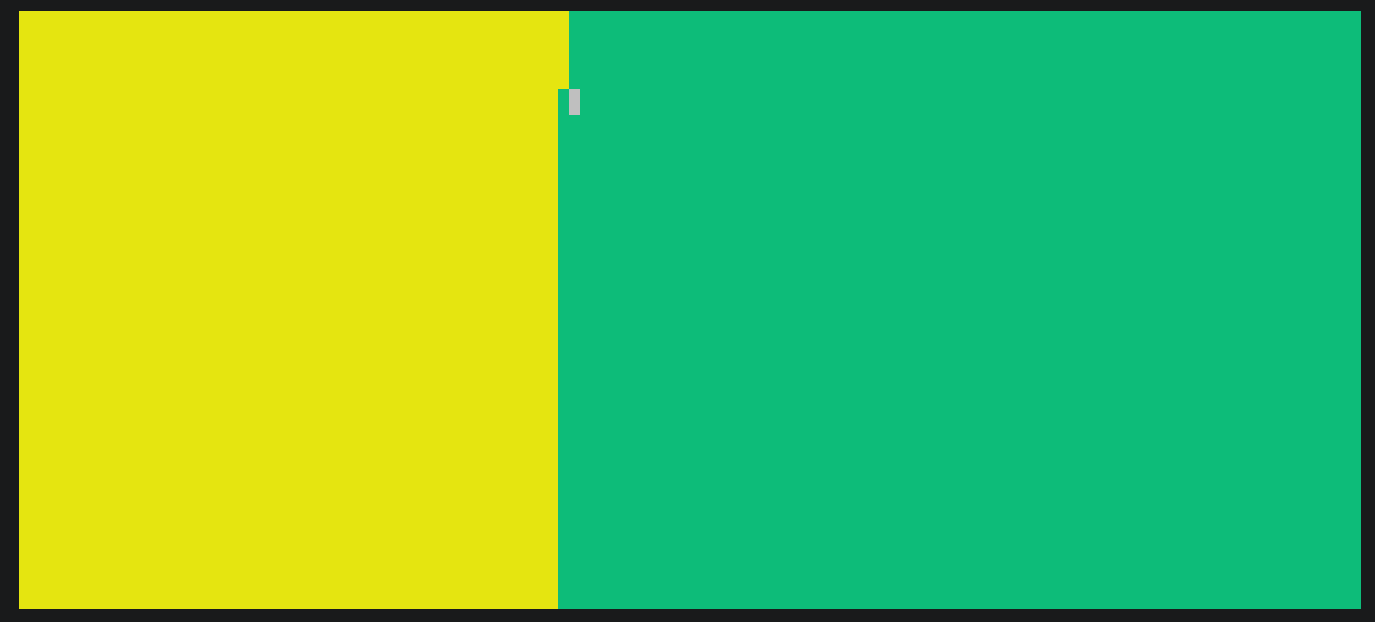
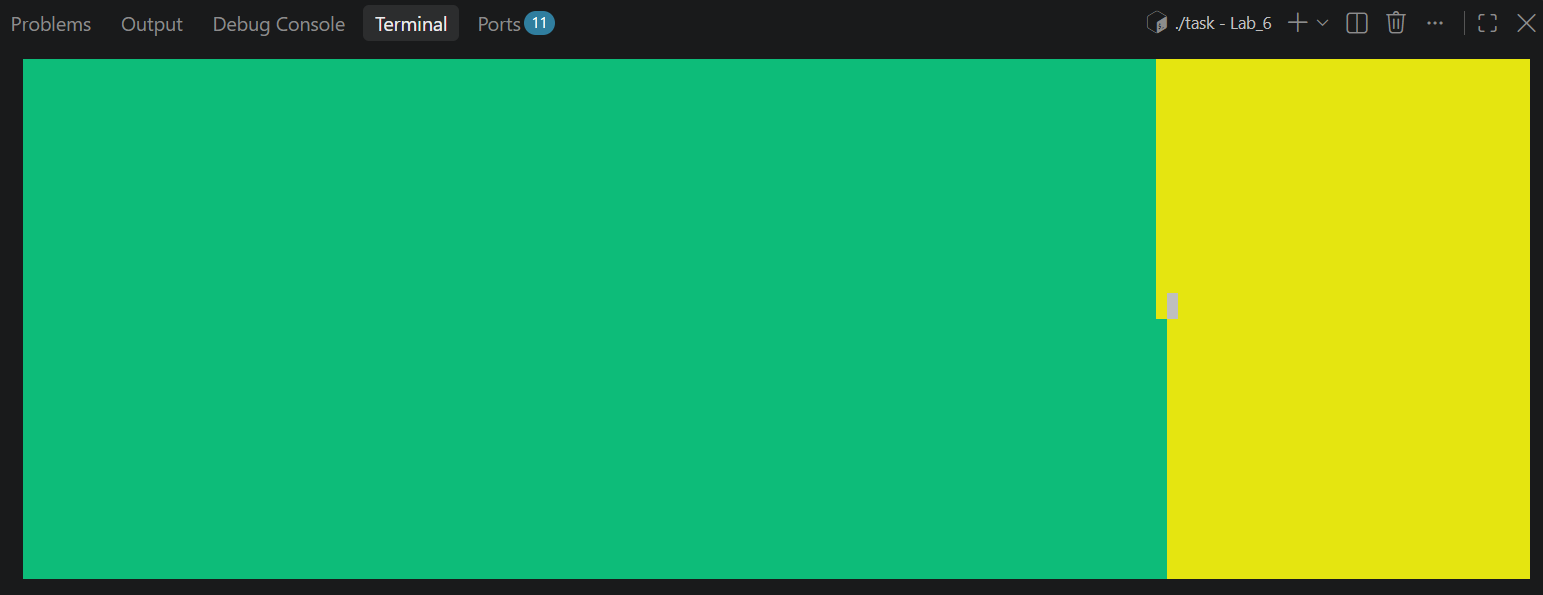